[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/shan4949/ml-visualized/blob/main/notebooks/11_svm.ipynb)

# 11 · Support Vector Machines: The Widest Street Between the Classes

**Part 1 — Classical supervised learning** · Notebook 11 of 27

Every classifier so far came from a probabilistic story. The support vector machine comes from **geometry** instead. ISYE 4600 (W9) puts its philosophy in one line: *instead of modeling probabilities, directly choose the most robust separating boundary.* "Most robust" means the boundary with the biggest **margin**, the widest empty street between the two classes. Turning that idea into an optimization problem, then into its **dual**, reveals three remarkable facts: the solution depends on only a handful of training points (the **support vectors**), it depends on the data only through **dot products**, and that second fact unlocks the **kernel trick**, which lets a linear method draw wildly nonlinear boundaries without ever computing the nonlinear features.

**What you'll learn**

1. Many lines separate the data. Which one is best?
2. The geometry of a hyperplane: normals, offsets and distances
3. The maximum-margin problem, solved from scratch
4. The **dual**: why only the support vectors matter (with Lagrange/KKT from notebook 03)
5. 🎚️ Move the points yourself: who's a support vector?
6. **Soft margins**: the $C$ parameter, and SVM = hinge loss + ridge
7. Training a linear SVM with stochastic subgradient descent (Pegasos)
8. **The kernel trick**: nonlinear boundaries from dot products
9. The RBF kernel, $C$ and $\gamma$, and a kernel SVM dual solved from scratch
10. SVMs in practice: multi-class, scaling, probabilities, and SVM vs. logistic regression

*Course map: ISYE 4600 W9 (Support Vector Machine: margins, primal and dual, KKT and support vectors, kernels, soft margin) and HW4 Q2 (SVM derivations and a small SVM by hand); W7 (KKT conditions); notebook 03, section 10.*

In [1]:
#@title ⚙️ Setup — run this cell first (imports, plot style, helpers)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import animation
from IPython.display import HTML, display, Markdown
import ipywidgets as widgets
from ipywidgets import interact, FloatSlider, IntSlider

# One consistent, colorblind-checked palette used across the whole series
C = dict(blue="#2a78d6", orange="#eb6834", aqua="#1baf7a", yellow="#eda100",
         magenta="#e87ba4", green="#008300", violet="#4a3aa7", red="#e34948",
         ink="#0b0b0b", muted="#52514e", light="#d9d8d3")
plt.rcParams.update({
    "figure.figsize": (6.4, 4.2), "figure.dpi": 100,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.8,
    "axes.axisbelow": True, "axes.titleweight": "bold", "axes.titlesize": 12,
    "axes.prop_cycle": plt.cycler(color=[C[k] for k in
        ["blue", "orange", "aqua", "yellow", "magenta", "green", "violet", "red"]]),
    "lines.linewidth": 2, "font.size": 11, "legend.frameon": False,
    "animation.embed_limit": 40, "animation.frame_format": "jpeg",   # JPEG frames keep notebooks small
})

def show_anim(anim):
    """Render a matplotlib animation as an interactive player (play / pause / scrub)."""
    plt.close(anim._fig)
    return HTML(anim.to_jshtml(default_mode="once"))

rng = np.random.default_rng(0)
print("Setup complete ✓")
from scipy.optimize import minimize
from sklearn.svm import SVC
from sklearn.datasets import make_moons, make_circles, make_blobs, load_digits
print("Ready ✓")

def plot_svm(ax, w, b, X, y, sv=None, lim=None, title="", shade=True, margin=True):
    """Decision boundary w·x + b = 0, margins w·x + b = ±1, and support vectors (circled). y ∈ {−1, +1}."""
    lim = lim or (X[:, 0].min() - 1, X[:, 0].max() + 1, X[:, 1].min() - 1, X[:, 1].max() + 1)
    g1, g2 = np.meshgrid(np.linspace(lim[0], lim[1], 300), np.linspace(lim[2], lim[3], 300))
    F = w[0] * g1 + w[1] * g2 + b
    if shade: ax.contourf(g1, g2, F, levels=[-1e9, 0, 1e9], colors=[C["blue"], C["red"]], alpha=0.12)
    ax.contour(g1, g2, F, levels=[0], colors=C["ink"], linewidths=2.2)
    if margin: ax.contour(g1, g2, F, levels=[-1, 1], colors=C["ink"], linewidths=1.2, linestyles="--")
    ax.scatter(*X[y == -1].T, s=40, color=C["blue"], edgecolor="white", zorder=3)
    ax.scatter(*X[y == 1].T, s=40, color=C["red"], edgecolor="white", zorder=3)
    if sv is not None and len(sv):
        ax.scatter(*X[sv].T, s=170, facecolor="none", edgecolor=C["ink"], lw=2, zorder=4)
    ax.set(xlim=lim[:2], ylim=lim[2:], aspect="equal", title=title); ax.grid(False)

Setup complete ✓


Ready ✓


---
## 1. Many lines separate the data. Which one is best?

When two classes are **linearly separable**, infinitely many lines get every training point right (ISYE W9: "all these boundaries achieve zero training error; the key question is generalization"). Logistic regression on separable data doesn't even have a unique answer (notebook 08, section 7). Here are three perfectly valid separators:

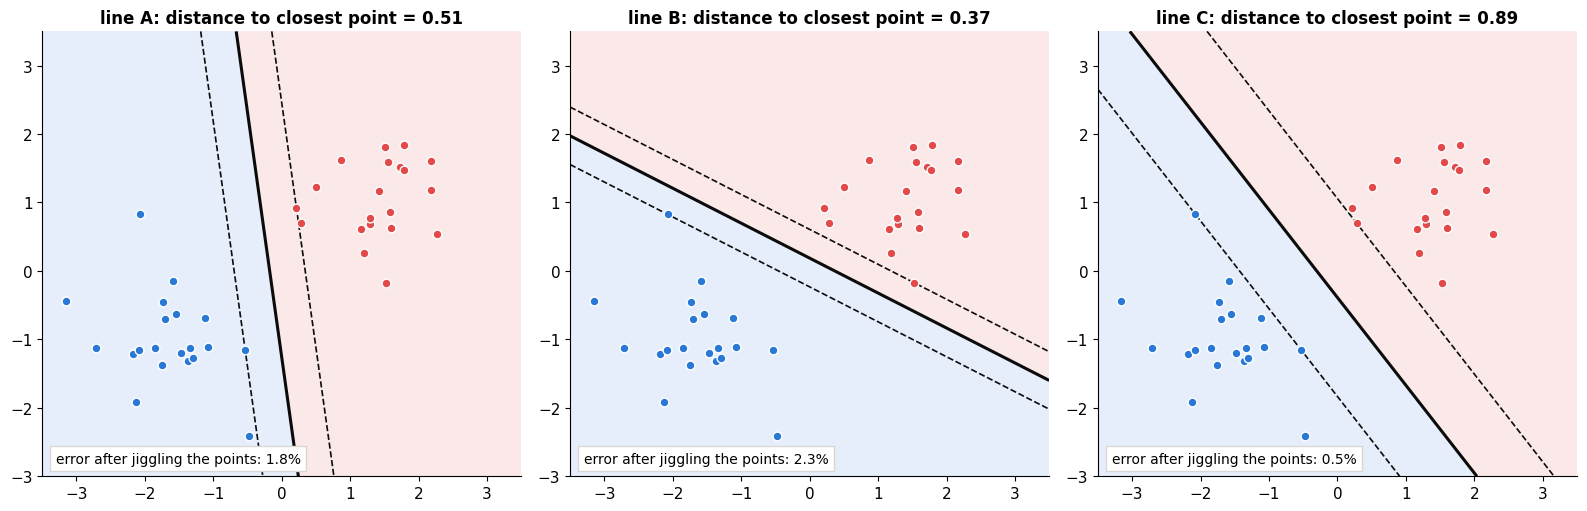

In [2]:
r_ = np.random.default_rng(3)
Xa = np.vstack([r_.normal([-1.6, -1.0], 0.55, size=(20, 2)), r_.normal([1.4, 1.2], 0.55, size=(20, 2))])
ya = np.r_[-np.ones(20), np.ones(20)]
# Three separating lines: rotate the best direction by −30°, +25° and 0°, and center each line in its own gap
w_best = SVC(kernel="linear", C=1e8).fit(Xa, ya).coef_[0]; ang0 = np.arctan2(w_best[1], w_best[0])
candidates = []
for name, dang in [("line A", -30), ("line B", 25), ("line C", 0)]:
    a = ang0 + np.radians(dang); s_ = np.array([np.cos(a), np.sin(a)])          # unit normal
    proj = Xa @ s_
    lo, hi = proj[ya == -1].max(), proj[ya == 1].min()                             # the empty gap along this direction
    candidates.append((s_, -(lo + hi) / 2, (hi - lo) / 2, name))

fig, axes = plt.subplots(1, 3, figsize=(16, 5.2))
for ax, (s_, b_, gap, name) in zip(axes, candidates):
    plot_svm(ax, s_ / gap, b_ / gap, Xa, ya, lim=(-3.5, 3.5, -3, 3.5), title=f"{name}: distance to closest point = {gap:.2f}")
    errs = np.mean([np.mean(np.sign((Xa + np.random.default_rng(t).normal(0, 0.5, Xa.shape)) @ s_ + b_) != ya) for t in range(300)])
    ax.text(-3.3, -2.8, f"error after jiggling the points: {errs:.1%}", fontsize=10, bbox=dict(facecolor="white", edgecolor=C["light"]))
fig.tight_layout(); plt.show()

All three classify the training data perfectly, but they differ in how close they come to the nearest points. The dashed lines mark the "street" around each boundary: as wide as possible while staying empty. When we jiggle every point by a little random noise (a stand-in for new test data that's similar but not identical), the line with the **widest street** makes the fewest mistakes. That's the SVM's whole bet: **maximize the margin**, the distance from the boundary to the closest training point.

---
## 2. The geometry of a hyperplane

A linear boundary is the set $\{x : w^\top x + b = 0\}$ (ISYE W9). Two facts make everything else work:

- **$w$ is perpendicular to the boundary.** For any two points $x_1, x_2$ on it, $w^\top(x_1 - x_2) = 0$, so $w$ is orthogonal to every direction lying in the boundary. $w$ sets the **orientation**; $b$ shifts it.
- **The signed distance** from a point $x$ to the boundary is

$$\text{dist}(x) = \frac{w^\top x + b}{\|w\|}$$

Derivation: decompose $x = x_\perp + r\,\frac{w}{\|w\|}$ where $x_\perp$ is its projection onto the boundary ($w^\top x_\perp + b = 0$) and $r$ is the distance along the normal. Then $w^\top x + b = w^\top x_\perp + b + r\frac{w^\top w}{\|w\|} = r\|w\|$, so $r = (w^\top x + b)/\|w\|$.

Notice that **scaling** $(w, b)$ by any positive constant leaves the boundary and these distances unchanged. That freedom is what we'll exploit next.

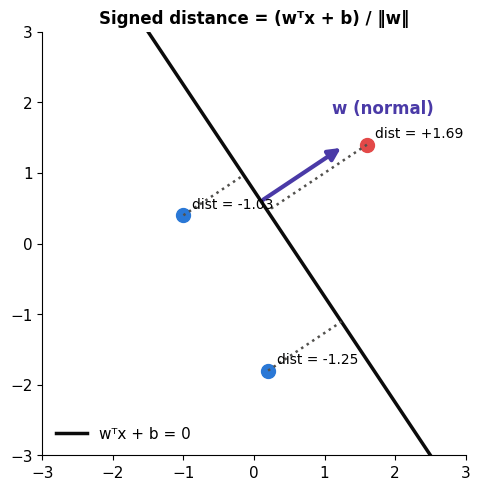

In [3]:
w_demo, b_demo = np.array([1.2, 0.8]), -0.6
pts = np.array([[1.6, 1.4], [-1.0, 0.4], [0.2, -1.8]])
fig, ax = plt.subplots(figsize=(6, 5.5))
g = np.linspace(-3, 3, 2)
ax.plot(g, (-b_demo - w_demo[0] * g) / w_demo[1], color=C["ink"], lw=2.5, label="wᵀx + b = 0")
ax.annotate("", xy=w_demo / np.linalg.norm(w_demo) * 1.4 + [0.1, 0.6], xytext=[0.1, 0.6], arrowprops=dict(arrowstyle="-|>", color=C["violet"], lw=3, mutation_scale=18))
ax.text(1.1, 1.85, "w (normal)", color=C["violet"], fontsize=12, fontweight="bold")
for p_ in pts:
    d_ = (w_demo @ p_ + b_demo) / np.linalg.norm(w_demo)
    foot = p_ - d_ * w_demo / np.linalg.norm(w_demo)
    ax.plot(*p_, "o", ms=10, color=C["red"] if d_ > 0 else C["blue"])
    ax.plot([p_[0], foot[0]], [p_[1], foot[1]], color=C["muted"], ls=":", lw=1.8)
    ax.text(p_[0] + 0.12, p_[1] + 0.1, f"dist = {d_:+.2f}", fontsize=10)
ax.set(xlim=(-3, 3), ylim=(-3, 3), aspect="equal", title="Signed distance = (wᵀx + b) / ‖w‖"); ax.legend(loc="lower left"); ax.grid(False)
plt.show()

---
## 3. The maximum-margin problem

With labels $y^i \in \{-1, +1\}$, a point is correctly classified with a cushion of at least $c$ if $y^i(w^\top x^i + b) \ge c$. The margin is then $\gamma = c/\|w\|$ on each side (the street's half-width; ISYE uses the full width $2c/\|w\|$, which changes nothing).

Because rescaling $(w, b)$ doesn't change the boundary, we can **fix $c = 1$** (ISYE HW4 asks exactly why: $c$ only scales $w$ and $b$, it doesn't change which boundary is better). Maximizing $1/\|w\|$ is the same as minimizing $\frac12\|w\|^2$, so the **hard-margin SVM** is

$$\min_{w,\,b}\;\frac12\|w\|^2 \qquad\text{subject to}\qquad y^i\big(w^\top x^i + b\big) \ge 1 \quad\text{for all } i$$

A **convex quadratic program**: a quadratic objective with linear constraints. It has a unique global optimum (notebook 03). Let's solve it directly with a general-purpose constrained optimizer:

ours:          w = [0.8868 0.6912], b = 0.2688,  margin = 1/‖w‖ = 0.8894
scikit-learn:  w = [0.8868 0.6916], b = 0.2688
points sitting exactly on the margin (y·f(x) = 1): [4, 13, 32]  ← the support vectors (sklearn says [4, 13, 32])


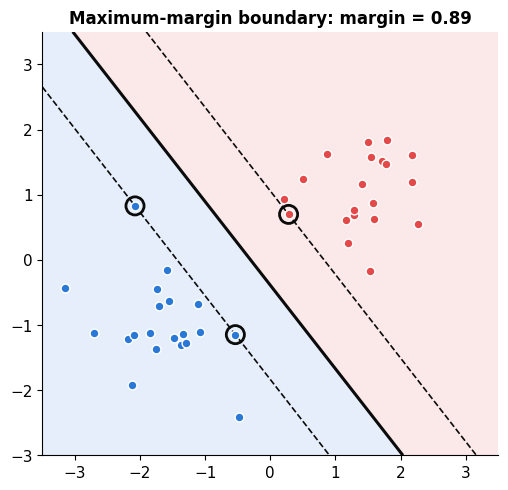

In [4]:
def svm_primal(X, y):
    d = X.shape[1]
    obj = lambda v: 0.5 * v[:d] @ v[:d]                           # v = [w, b]
    cons = [{"type": "ineq", "fun": lambda v: y * (X @ v[:d] + v[d]) - 1, "jac": lambda v: np.column_stack([y[:, None] * X, y])}]
    v = minimize(obj, x0=np.zeros(d + 1), jac=lambda v: np.r_[v[:d], 0], constraints=cons, method="SLSQP").x
    return v[:d], v[d]

w_p, b_p = svm_primal(Xa, ya)
margins = ya * (Xa @ w_p + b_p)
sv_p = np.where(margins < 1 + 1e-4)[0]
sk = SVC(kernel="linear", C=1e8).fit(Xa, ya)
print(f"ours:          w = {w_p.round(4)}, b = {b_p:.4f},  margin = 1/‖w‖ = {1/np.linalg.norm(w_p):.4f}")
print(f"scikit-learn:  w = {sk.coef_[0].round(4)}, b = {sk.intercept_[0]:.4f}")
print(f"points sitting exactly on the margin (y·f(x) = 1): {sv_p.tolist()}  ← the support vectors (sklearn says {sk.support_.tolist()})")

fig, ax = plt.subplots(figsize=(6.5, 5.5))
plot_svm(ax, w_p, b_p, Xa, ya, sv=sv_p, lim=(-3.5, 3.5, -3, 3.5), title=f"Maximum-margin boundary: margin = {1/np.linalg.norm(w_p):.2f}")
plt.show()

The widest street is pinned in place by just **three** points touching its edges (circled). Those are the **support vectors**. Section 4 explains why they, and only they, matter.

> 🤔 **Question: Why maximize the *minimum* distance, rather than the average distance to all points?**
>
> (ISYE W9 asks this too.) The average would be dominated by the many easy points far from the boundary, which say nothing about where the classes actually meet. The minimum focuses on the points that are hardest to classify, the ones near the frontier, which is where new test points are most likely to be misclassified. There's also theory: generalization bounds for large-margin classifiers depend on the margin relative to the size of the data, not on the number of features, which is part of why SVMs work well even in very high dimensions.

---
## 4. The dual: why only the support vectors matter

Now bring in the Lagrangian machinery from notebook 03 (ISYE W7 and W9). Rewrite each constraint as $g_i = 1 - y^i(w^\top x^i + b) \le 0$ and attach a multiplier $\alpha_i \ge 0$:

$$\mathcal{L}(w, b, \alpha) = \frac12 w^\top w + \sum_{i=1}^m \alpha_i\Big[1 - y^i\big(w^\top x^i + b\big)\Big]$$

**Step 1: stationarity.** Set the derivatives with respect to the primal variables to zero:

$$\frac{\partial\mathcal{L}}{\partial w} = w - \sum_i \alpha_i y^i x^i = 0 \;\;\Longrightarrow\;\; \boxed{w = \sum_{i=1}^m \alpha_i y^i x^i} \qquad\qquad \frac{\partial\mathcal{L}}{\partial b} = -\sum_i \alpha_i y^i = 0$$

The optimal $w$ is a **weighted combination of the training points** (ISYE HW4's question 2).

**Step 2: plug back in.** Substituting $w$ eliminates $w$ and $b$ and leaves a problem in $\alpha$ alone, the **dual**:

$$\max_{\alpha}\;\sum_i \alpha_i - \frac12\sum_{i,j}\alpha_i\alpha_j\,y^i y^j\,\big(x^{i\top}x^j\big) \qquad\text{subject to}\qquad \alpha_i \ge 0,\;\; \sum_i \alpha_i y^i = 0$$

Another convex QP, with one variable per training point. Notice the data enters **only through dot products** $x^{i\top}x^j$. Hold that thought until section 8.

**Step 3: complementary slackness** (KKT, notebook 03): at the optimum, $\alpha_i\big[1 - y^i(w^\top x^i + b)\big] = 0$ for every $i$. So for each point, either

- $y^i(w^\top x^i + b) > 1$ (it's strictly outside the street), and then $\alpha_i = 0$: it contributes **nothing** to $w$; or
- $\alpha_i > 0$, and then $y^i(w^\top x^i + b) = 1$: it sits exactly **on** the margin. These are the support vectors.

That's why only the support vectors matter (ISYE HW4 question 3): every other point has $\alpha_i = 0$ and drops out of $w = \sum_i\alpha_i y^i x^i$. Delete all the other points and retrain: you get the same boundary. Let's solve the dual ourselves and check:

In [5]:
def svm_dual(K, y, C=None):
    """Maximize Σα − ½ αᵀ(yyᵀ∘K)α  s.t. 0 ≤ α (≤ C for soft margin), Σαy = 0.  K = Gram matrix of dot products (or kernel values)."""
    m = len(y); Q = (y[:, None] * y[None, :]) * K
    obj = lambda a: 0.5 * a @ Q @ a - a.sum()                     # minimize the negative
    jac = lambda a: Q @ a - 1
    bounds = [(0, C)] * m
    cons = [{"type": "eq", "fun": lambda a: a @ y, "jac": lambda a: y}]
    return minimize(obj, x0=np.zeros(m), jac=jac, bounds=bounds, constraints=cons, method="SLSQP", options=dict(maxiter=500, ftol=1e-12)).x

alpha = svm_dual(Xa @ Xa.T, ya)
w_d = (alpha * ya) @ Xa                                           # w = Σ α_i y_i x_i
sv_d = np.where(alpha > 1e-5)[0]
b_d = np.mean(ya[sv_d] - Xa[sv_d] @ w_d)                          # from y_i (wᵀx_i + b) = 1 on the support vectors
print("nonzero α's:", {int(i): round(float(alpha[i]), 4) for i in sv_d})
print(f"w from the dual = {w_d.round(4)},  b = {b_d:.4f}")
print(f"w from the primal = {w_p.round(4)},  b = {b_p:.4f}")
print(f"{len(sv_d)} of {len(ya)} points have α > 0; the other {len(ya) - len(sv_d)} have α = 0 and don't affect the boundary at all")

w_sv, b_sv = svm_primal(Xa[sv_d], ya[sv_d])
print(f"\nRetrained on ONLY the {len(sv_d)} support vectors: w = {w_sv.round(4)}, b = {b_sv:.4f}  (identical)")

nonzero α's: {4: 0.2405, 13: 0.3916, 32: 0.6321}
w from the dual = [0.8868 0.6912],  b = 0.2688
w from the primal = [0.8868 0.6912],  b = 0.2688
3 of 40 points have α > 0; the other 37 have α = 0 and don't affect the boundary at all

Retrained on ONLY the 3 support vectors: w = [0.8868 0.6912], b = 0.2688  (identical)


The dual gives the same boundary as the primal, only 3 of the 40 points have nonzero $\alpha$, and retraining on those 3 alone reproduces the boundary exactly. ISYE W9 calls this a kind of data compression: the classifier is defined by a small set of critical points. To classify a new point $z$:

$$f(z) = \text{sign}\Big(\sum_{i\,\in\,\text{SV}} \alpha_i y^i\, x^{i\top} z + b\Big)$$

which compares $z$ with the support vectors only.

---
## 5. 🎚️ Move the points yourself: who's a support vector?

Here are five points. Drag one red point around with the sliders. As long as it stays outside the street, **nothing changes**: it isn't a support vector. The moment it presses against the street, it becomes one and starts pushing the boundary around. If it crosses to the other side, the data stops being separable and the hard-margin problem has no solution (section 6 fixes that).

In [6]:
X5 = np.array([[0.0, 0.0], [1.0, 2.5], [3.0, 1.0], [3.5, 3.5], [0.5, 3.8]]); y5 = np.array([-1, -1, 1, 1, -1])

def plot_drag(px=4.0, py=2.0):
    X_ = X5.copy(); X_[3] = [px, py]
    sk_ = SVC(kernel="linear", C=1e6).fit(X_, y5)
    w_, b_ = sk_.coef_[0], sk_.intercept_[0]
    separable = np.all(sk_.predict(X_) == y5)
    fig, ax = plt.subplots(figsize=(6.5, 5.6))
    plot_svm(ax, w_, b_, X_, y5, sv=sk_.support_, lim=(-1.5, 5.5, -1.5, 5.5),
             title=f"margin = {1/np.linalg.norm(w_):.2f},  support vectors: {len(sk_.support_)}" + ("" if separable else "   (NOT separable!)"))
    ax.plot(px, py, "s", ms=14, mfc="none", mec=C["orange"], mew=2.5)
    ax.text(px + 0.15, py + 0.2, "drag me", color=C["orange"], fontsize=10)
    plt.show()

interact(plot_drag, px=FloatSlider(value=4.0, min=-1, max=5.5, step=0.1, description="red point x"),
         py=FloatSlider(value=2.0, min=-1, max=5.5, step=0.1, description="red point y"));

Contrast this with logistic regression, where **every** training point pulls on the boundary a little (its gradient is $\sum_i (\sigma - y^i)x^i$ over all points). The SVM is decided by the frontier alone. That's a strength (robust to how many easy points there are) and a weakness (sensitive to a few mislabeled points near the boundary).

---
## 6. Soft margins: the $C$ parameter, and SVM = hinge loss + ridge

Real data is rarely separable, and even when it is, insisting on zero training errors lets one outlier dictate the boundary. The **soft-margin SVM** (ISYE W9) allows violations: each point gets a **slack** $\xi_i \ge 0$ measuring how far it falls short of the margin, and we pay $C$ per unit of slack:

$$\min_{w,\,b,\,\xi}\;\frac12\|w\|^2 + C\sum_i \xi_i \qquad\text{subject to}\qquad y^i(w^\top x^i + b) \ge 1 - \xi_i,\quad \xi_i \ge 0$$

- $0 < \xi_i < 1$: inside the street but still on the correct side.
- $\xi_i > 1$: misclassified.

**$C$ controls the tradeoff.** Large $C$: violations are expensive, so the street narrows to avoid them (low bias, high variance; $C \to \infty$ is the hard margin). Small $C$: a wide street that tolerates violations (high bias, low variance).

In the dual, the only change is a **box constraint**, $0 \le \alpha_i \le C$. Support vectors are now all points on or inside the street, or on the wrong side.

### The same thing as a loss function

At the optimum, each slack is as small as allowed: $\xi_i = \max\big(0,\, 1 - y^i f(x^i)\big)$ with $f(x) = w^\top x + b$. Substitute, and divide by $Cm$:

$$\min_{w,b}\;\frac1m\sum_{i=1}^m \underbrace{\max\big(0,\,1 - y^i f(x^i)\big)}_{\text{hinge loss}} \;+\; \frac{\lambda}{2}\|w\|^2, \qquad \lambda = \frac{1}{Cm}$$

So the soft-margin SVM is just **regularized empirical risk minimization** with the **hinge loss** plus a **ridge** penalty, the same template as notebooks 05–08 (ISYE W7's template). Notebook 08 already drew the hinge loss next to the logistic loss: they're close cousins, except the hinge is exactly zero for points safely outside the margin, which is what makes the solution depend only on the support vectors.

🎚️ **Change $C$** on overlapping data and watch the street, the support vectors, and the training errors:

In [7]:
Xo, yo = make_blobs(n_samples=120, centers=[[-1.2, -0.8], [1.2, 0.8]], cluster_std=1.1, random_state=2); yo = 2 * yo - 1.0

def plot_soft(log10_C=0.0):
    Cv = 10 ** log10_C
    sk_ = SVC(kernel="linear", C=Cv).fit(Xo, yo)
    w_, b_ = sk_.coef_[0], sk_.intercept_[0]
    xi = np.maximum(0, 1 - yo * (Xo @ w_ + b_))
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.8), gridspec_kw=dict(width_ratios=[1.2, 1]))
    plot_svm(ax1, w_, b_, Xo, yo, sv=sk_.support_, lim=(-4.5, 4.5, -4, 4),
             title=f"C = {Cv:.3g}: margin {1/np.linalg.norm(w_):.2f}, {len(sk_.support_)} support vectors, {int(np.sum(sk_.predict(Xo) != yo))} training errors")
    order = np.argsort(-xi)
    ax2.bar(range(len(xi)), xi[order], color=[C["red"] if v > 1 else C["orange"] if v > 0 else C["light"] for v in xi[order]])
    ax2.axhline(1, color=C["ink"], ls="--", lw=1); ax2.text(len(xi) * 0.55, 1.08, "ξ > 1: misclassified", fontsize=9)
    ax2.set(xlabel="training points (sorted)", ylabel="slack ξᵢ = max(0, 1 − yᵢ f(xᵢ))", title=f"slack: total Σξ = {xi.sum():.1f}", ylim=(0, max(3, xi.max() * 1.1)))
    fig.tight_layout(); plt.show()

interact(plot_soft, log10_C=FloatSlider(value=0.0, min=-3, max=3, step=0.25, description="log₁₀ C"));

---
## 7. Training a linear SVM with stochastic subgradient descent (Pegasos)

The hinge-loss form opens up a second way to train: gradient descent, no QP solver needed. The hinge has a kink at margin 1, so we use a **subgradient**: for a point with $y^i f(x^i) < 1$ the gradient of its hinge term is $-y^i x^i$; otherwise it's $0$. The **Pegasos** algorithm (Shalev-Shwartz et al., 2007) is SGD on this objective with step size $\eta_t = 1/(\lambda t)$:

$$w \leftarrow (1 - \eta_t\lambda)\,w + \eta_t\,\mathbb{1}\big[y^i f(x^i) < 1\big]\,y^i x^i$$

Read it in words: **shrink $w$ a little** (the ridge term), and **if the sampled point is inside the street or wrong, nudge $w$ toward classifying it correctly.** Points safely outside the margin cause no update at all. This scales to millions of examples, and it's how linear SVMs are trained on large text datasets.

In [8]:
def pegasos(X, y, lam, epochs=30, seed=0, record=50):
    r2 = np.random.default_rng(seed); m = len(y)
    Xb_ = np.column_stack([X, np.ones(m)])                       # fold the bias in as an extra (lightly regularized) weight
    w = np.zeros(Xb_.shape[1]); t = 0; hist = []
    for ep in range(epochs):
        for i in r2.permutation(m):
            t += 1; eta = 1.0 / (lam * t)
            viol = y[i] * (Xb_[i] @ w) < 1
            w *= (1 - eta * lam)
            if viol: w += eta * y[i] * Xb_[i]
            if t % record == 0: hist.append(w.copy())
    return w, hist

lam_o = 1 / (1.0 * len(yo))                                       # λ = 1/(C m) with C = 1
w_peg, hist_peg = pegasos(Xo, yo, lam_o, epochs=40)
sk1 = SVC(kernel="linear", C=1.0).fit(Xo, yo)
print(f"Pegasos:       w = {w_peg[:2].round(3)}, b = {w_peg[2]:.3f}")
print(f"scikit-learn:  w = {sk1.coef_[0].round(3)}, b = {sk1.intercept_[0]:.3f}   (Pegasos also shrinks the bias slightly, so b differs a bit)")

fig, ax = plt.subplots(figsize=(6.2, 5.3), dpi=72)
g1, g2 = np.meshgrid(np.linspace(-4.5, 4.5, 2), np.linspace(-4, 4, 2))
ax.scatter(*Xo[yo == -1].T, s=22, color=C["blue"]); ax.scatter(*Xo[yo == 1].T, s=22, color=C["red"])
xs_ = np.linspace(-4.5, 4.5, 2)
ln, = ax.plot([], [], color=C["ink"], lw=2.2); lu, = ax.plot([], [], color=C["ink"], lw=1, ls="--"); ll, = ax.plot([], [], color=C["ink"], lw=1, ls="--")
ax.set(xlim=(-4.5, 4.5), ylim=(-4, 4), aspect="equal"); ax.grid(False); ttl = ax.set_title("")
def frame(k):
    w_ = hist_peg[k]
    for line, off in [(ln, 0), (lu, 1), (ll, -1)]:
        line.set_data(xs_, (off - w_[2] - w_[0] * xs_) / w_[1])
    ttl.set_text(f"Pegasos after {(k + 1) * 50} single-point updates")
    return ln, lu, ll
frames = [0, 1, 2, 3, 4, 6, 8, 11, 15, 20, 26, 33, 41, 50, 62, 75, len(hist_peg) - 1]
show_anim(animation.FuncAnimation(fig, frame, frames=frames, interval=250))

Pegasos:       w = [1.53  0.837], b = 0.125
scikit-learn:  w = [1.618 0.86 ], b = 0.209   (Pegasos also shrinks the bias slightly, so b differs a bit)


---
## 8. The kernel trick

Now the payoff of "the data enters only through dot products." Take data that no line can separate, like a ring around a blob. Map each point into a higher-dimensional space where it *is* linearly separable. For circles, the map

$$\phi(x_1, x_2) = \big(x_1^2,\;\; \sqrt2\,x_1x_2,\;\; x_2^2\big)$$

turns "distance from the origin" into a linear function ($x_1^2 + x_2^2$ is a sum of two coordinates), so in 3-D a flat plane separates the inner and outer classes:

In [9]:
Xc, yc = make_circles(n_samples=200, noise=0.08, factor=0.45, random_state=1); yc = 2 * yc - 1.0
phi = lambda X: np.column_stack([X[:, 0] ** 2, np.sqrt(2) * X[:, 0] * X[:, 1], X[:, 1] ** 2])
P3 = phi(Xc)
sk3 = SVC(kernel="linear", C=10).fit(P3, yc); w3, b3 = sk3.coef_[0], sk3.intercept_[0]

def plot_lift(elev=18, azim=-60):
    fig = plt.figure(figsize=(13, 5))
    ax1 = fig.add_subplot(121)
    ax1.scatter(*Xc[yc == -1].T, s=14, color=C["blue"]); ax1.scatter(*Xc[yc == 1].T, s=14, color=C["red"])
    g1, g2 = np.meshgrid(np.linspace(-1.4, 1.4, 300), np.linspace(-1.4, 1.4, 300))
    F = phi(np.column_stack([g1.ravel(), g2.ravel()])) @ w3 + b3
    ax1.contour(g1, g2, F.reshape(g1.shape), levels=[0], colors=C["ink"], linewidths=2)
    ax1.set(aspect="equal", title="Original space: no line works, but the lifted plane\nprojects back to this ellipse"); ax1.grid(False)
    ax2 = fig.add_subplot(122, projection="3d")
    ax2.scatter(*P3[yc == -1].T, s=10, color=C["blue"]); ax2.scatter(*P3[yc == 1].T, s=10, color=C["red"])
    u, v = np.meshgrid(np.linspace(0, 1.6, 20), np.linspace(-1.6, 1.6, 20))       # u = x₁², v = √2·x₁x₂
    zp = (-b3 - w3[0] * u - w3[1] * v) / w3[2]                                       # solve the plane for x₂²
    zp = np.where((zp >= 0) & (zp <= 1.7), zp, np.nan)
    ax2.plot_surface(u, v, zp, alpha=0.3, color=C["violet"])
    ax2.set(xlabel="x₁²", ylabel="√2·x₁x₂", zlabel="x₂²", title="Lifted to 3-D: a flat plane separates them")
    ax2.view_init(elev=elev, azim=azim)
    plt.show()

interact(plot_lift, elev=IntSlider(value=18, min=0, max=90, step=6, description="elevation"),
         azim=IntSlider(value=-60, min=-180, max=180, step=10, description="azimuth"));

Now the trick. To train an SVM in the lifted space, the dual only needs dot products $\phi(x)^\top\phi(z)$. Compute one:

$$\phi(x)^\top\phi(z) = x_1^2z_1^2 + 2x_1x_2z_1z_2 + x_2^2z_2^2 = (x_1z_1 + x_2z_2)^2 = (x^\top z)^2$$

The dot product in the 3-D feature space equals $(x^\top z)^2$, computed **entirely in the original 2-D space**, without ever building $\phi$. A function $k(x, z)$ that equals $\phi(x)^\top\phi(z)$ for some feature map is a **kernel**. Swap every $x^{i\top}x^j$ in the dual for $k(x^i, x^j)$, and the classifier for $k(x^i, z)$ (ISYE W9):

$$f(z) = \text{sign}\Big(\sum_{i\,\in\,\text{SV}}\alpha_i y^i\,k(x^i, z) + b\Big)$$

and you're running a linear SVM in feature space while only ever computing kernels.

In [10]:
xq, zq = np.array([0.7, -1.3]), np.array([1.5, 0.4])
print(f"φ(x)·φ(z) computed in 3-D: {phi(xq[None])[0] @ phi(zq[None])[0]:.6f}")
print(f"(x·z)² computed in 2-D:    {(xq @ zq) ** 2:.6f}")
print("\nFor the degree-d polynomial kernel (x·z + 1)^d in p dimensions, the hidden feature space has C(p+d, d) dimensions:")
from math import comb
for p_, d_ in [(2, 2), (64, 3), (784, 5)]:
    print(f"   p = {p_:4d}, d = {d_}:  {comb(p_ + d_, d_):>15,} features, but each kernel evaluation costs O(p)")

φ(x)·φ(z) computed in 3-D: 0.280900
(x·z)² computed in 2-D:    0.280900

For the degree-d polynomial kernel (x·z + 1)^d in p dimensions, the hidden feature space has C(p+d, d) dimensions:
   p =    2, d = 2:                6 features, but each kernel evaluation costs O(p)
   p =   64, d = 3:           47,905 features, but each kernel evaluation costs O(p)
   p =  784, d = 5:  2,515,874,132,157 features, but each kernel evaluation costs O(p)


That last line is why kernels matter: a degree-5 polynomial kernel on 784-pixel images works implicitly with about 2.5 × 10¹² features, which you could never write down, at the cost of one 784-dimensional dot product per kernel evaluation.

---
## 9. The RBF kernel, $C$ and $\gamma$

The most popular kernel is the **Gaussian radial basis function** (ISYE W9):

$$k(x, z) = \exp\big(-\gamma\|x - z\|^2\big), \qquad \gamma = \frac{1}{2\sigma^2}$$

It's a **similarity**: 1 for identical points, decaying to 0 as they move apart. Its feature space is **infinite-dimensional** (expand the exponential as a power series), yet each evaluation is one distance computation. The classifier $f(z) = \sum_i \alpha_i y^i\, e^{-\gamma\|x^i - z\|^2} + b$ is a weighted sum of Gaussian bumps centered on the support vectors (much like notebook 05's RBF basis functions, but with the centers and weights chosen by the optimization).

Let's solve the kernelized soft-margin dual **ourselves** (it's the same `svm_dual` function, now handed a kernel matrix) and check against scikit-learn:

In [11]:
def rbf_kernel(A, B, gamma):
    return np.exp(-gamma * np.maximum((A ** 2).sum(1)[:, None] + (B ** 2).sum(1)[None, :] - 2 * A @ B.T, 0))

Xmn, ymn = make_moons(n_samples=120, noise=0.2, random_state=0); ymn = 2 * ymn - 1.0
gamma_, C_ = 1.0, 3.0
alpha_k = svm_dual(rbf_kernel(Xmn, Xmn, gamma_), ymn, C=C_)
sv_k = np.where(alpha_k > 1e-6)[0]
on_margin = np.where((alpha_k > 1e-6) & (alpha_k < C_ - 1e-6))[0]           # 0 < α < C: exactly on the margin
b_k = np.mean(ymn[on_margin] - rbf_kernel(Xmn[on_margin], Xmn, gamma_) @ (alpha_k * ymn))
f_ours = lambda Z: rbf_kernel(Z, Xmn, gamma_) @ (alpha_k * ymn) + b_k

sk_rbf = SVC(kernel="rbf", gamma=gamma_, C=C_).fit(Xmn, ymn)
grid = np.random.default_rng(0).uniform(-1.5, 2.5, size=(500, 2))
print(f"support vectors: ours {len(sv_k)}, scikit-learn {len(sk_rbf.support_)}")
print(f"decision agreement on 500 random points: {np.mean(np.sign(f_ours(grid)) == sk_rbf.predict(grid)):.1%}")
print(f"max |our decision function − sklearn's| = {np.abs(f_ours(grid) - sk_rbf.decision_function(grid)).max():.4f}")

support vectors: ours 27, scikit-learn 27
decision agreement on 500 random points: 100.0%
max |our decision function − sklearn's| = 0.0011


Two knobs, both about flexibility:

- **$\gamma$** sets the bump width. Small $\gamma$: wide bumps, smooth boundary (in the limit, nearly linear). Large $\gamma$: narrow bumps around each support vector, and the boundary can wrap around individual points (at the extreme, it memorizes the training set, like 1-nearest-neighbor).
- **$C$** sets the penalty for violations, as before.

🎚️ **Explore both on the moons.** Circled points are support vectors; dashed lines are the margins $f = \pm 1$.

In [12]:
Xm2, ym2 = make_moons(n_samples=200, noise=0.25, random_state=1); ym2 = 2 * ym2 - 1.0
Xv2, yv2 = make_moons(n_samples=1000, noise=0.25, random_state=7); yv2 = 2 * yv2 - 1.0

def plot_rbf(log10_gamma=0.0, log10_C=0.0):
    sk_ = SVC(kernel="rbf", gamma=10 ** log10_gamma, C=10 ** log10_C).fit(Xm2, ym2)
    g1, g2 = np.meshgrid(np.linspace(-1.7, 2.7, 250), np.linspace(-1.3, 1.8, 250))
    F = sk_.decision_function(np.column_stack([g1.ravel(), g2.ravel()])).reshape(g1.shape)
    fig, ax = plt.subplots(figsize=(8, 5.3))
    ax.contourf(g1, g2, F, levels=[-1e9, 0, 1e9], colors=[C["blue"], C["red"]], alpha=0.15)
    ax.contour(g1, g2, F, levels=[0], colors=C["ink"], linewidths=2); ax.contour(g1, g2, F, levels=[-1, 1], colors=C["ink"], linewidths=1, linestyles="--")
    ax.scatter(*Xm2[ym2 == -1].T, s=16, color=C["blue"]); ax.scatter(*Xm2[ym2 == 1].T, s=16, color=C["red"])
    ax.scatter(*Xm2[sk_.support_].T, s=70, facecolor="none", edgecolor=C["ink"], lw=1.2)
    ax.set(xlim=(-1.7, 2.7), ylim=(-1.3, 1.8), aspect="equal",
           title=f"γ = {10**log10_gamma:.3g}, C = {10**log10_C:.3g}:  train acc {sk_.score(Xm2, ym2):.0%},  test acc {sk_.score(Xv2, yv2):.0%},  {len(sk_.support_)} SVs")
    ax.grid(False); plt.show()

interact(plot_rbf, log10_gamma=FloatSlider(value=0.0, min=-2, max=2.5, step=0.25, description="log₁₀ γ"),
         log10_C=FloatSlider(value=0.0, min=-2, max=4, step=0.5, description="log₁₀ C"));

Large $\gamma$ with large $C$: 100% training accuracy, islands around single points, worse test accuracy (overfitting). Small $\gamma$ with small $C$: a nearly straight boundary (underfitting). In practice, $\gamma$ and $C$ are chosen together by cross-validation over a log-spaced grid:

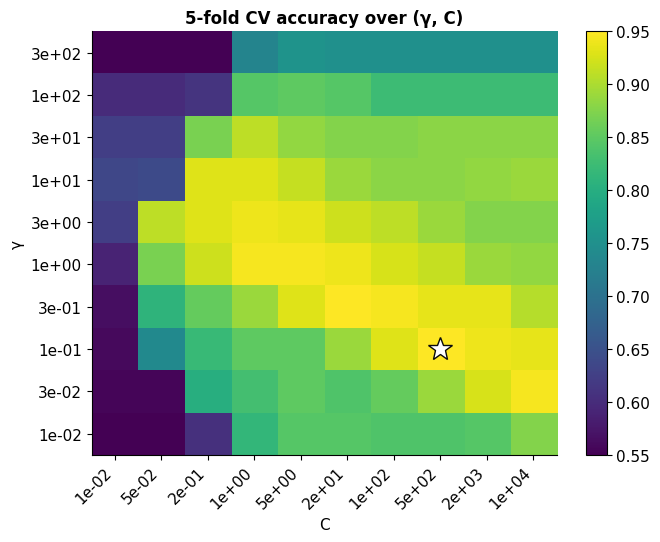

best: γ = 0.1, C = 464, CV accuracy 95.0%


In [13]:
gammas = np.logspace(-2, 2.5, 10); Cs = np.logspace(-2, 4, 10)
folds = np.array_split(np.random.default_rng(0).permutation(len(ym2)), 5)
cvacc = np.zeros((len(gammas), len(Cs)))
for i, gm in enumerate(gammas):
    for j, cv_ in enumerate(Cs):
        accs = []
        for va in folds:
            tr_ = np.setdiff1d(np.arange(len(ym2)), va)
            accs.append(SVC(kernel="rbf", gamma=gm, C=cv_).fit(Xm2[tr_], ym2[tr_]).score(Xm2[va], ym2[va]))
        cvacc[i, j] = np.mean(accs)
fig, ax = plt.subplots(figsize=(7.5, 5.5))
im = ax.imshow(cvacc, origin="lower", cmap="viridis", aspect="auto")
ax.set(xticks=range(len(Cs)), xticklabels=[f"{c:.0e}" for c in Cs], yticks=range(len(gammas)), yticklabels=[f"{g:.0e}" for g in gammas],
       xlabel="C", ylabel="γ", title="5-fold CV accuracy over (γ, C)")
plt.setp(ax.get_xticklabels(), rotation=45, ha="right"); plt.colorbar(im, ax=ax)
i_b, j_b = np.unravel_index(cvacc.argmax(), cvacc.shape)
ax.plot(j_b, i_b, "*", ms=18, color="white", markeredgecolor=C["ink"]); ax.grid(False); plt.show()
print(f"best: γ = {gammas[i_b]:.3g}, C = {Cs[j_b]:.3g}, CV accuracy {cvacc.max():.1%}")

Notice the diagonal ridge of good settings: larger $\gamma$ (more flexible bumps) pairs with smaller $C$ (more tolerance), and vice versa. Both knobs trade off the same thing.

> 🤔 **Question: Which functions are valid kernels?**
>
> A function $k(x, z)$ is a valid kernel (corresponds to a dot product in *some* feature space) exactly when every Gram matrix $K_{ij} = k(x^i, x^j)$ it produces is symmetric positive semi-definite (**Mercer's condition**; PSD matrices from notebook 01). Sums, products and positive multiples of kernels are kernels, which lets you build kernels for strings, graphs and molecules. The same trick powers **kernel ridge regression**, **kernel PCA**, and **Gaussian processes**.

---
## 10. SVMs in practice

**Multi-class.** SVMs are binary. Two standard wrappers (ISYE W9): **one-vs-rest** ($K$ classifiers, "class $k$ vs. everything else," predict the highest score) and **one-vs-one** ($K(K-1)/2$ classifiers, one per pair, majority vote; scikit-learn's `SVC` default). On the 8×8 digits from notebook 10:

In [14]:
dg = load_digits(); Xg, yg = dg.data / 16.0, dg.target
perm = np.random.default_rng(0).permutation(len(yg)); tr_g, te_g = perm[:1300], perm[1300:]
for name, mdl in [("linear SVM", SVC(kernel="linear", C=1.0)), ("RBF SVM (γ = 'scale')", SVC(kernel="rbf", C=10))]:
    mdl.fit(Xg[tr_g], yg[tr_g])
    print(f"{name:24s} test accuracy {mdl.score(Xg[te_g], yg[te_g]):.1%},  {mdl.n_support_.sum()} support vectors of {len(tr_g)} training images")

linear SVM               test accuracy 98.4%,  396 support vectors of 1300 training images
RBF SVM (γ = 'scale')    test accuracy 99.2%,  535 support vectors of 1300 training images


**Scale your features.** Like KNN (notebook 10), the RBF kernel is built on distances, so a feature in large units dominates. Standardize first (or the "scale" setting for $\gamma$ helps only partially).

**No probabilities out of the box.** The SVM outputs a signed distance $f(x)$, not a probability. `SVC(probability=True)` fits Platt scaling (a logistic regression on $f$, notebook 10) with internal cross-validation, which is slow and only approximately calibrated.

**Cost.** Kernel SVMs need the $m\times m$ kernel matrix and training time between $O(m^2)$ and $O(m^3)$. They're excellent up to tens of thousands of examples, impractical for millions. For big data, use a linear SVM trained with SGD (section 7) or approximate the kernel with random features (notebook 06's double-descent experiment used them).

**SVM vs. logistic regression** (ISYE W9):

| | SVM | Logistic regression |
|---|---|---|
| Objective | max margin (hinge loss + $\ell_2$) | max likelihood (log loss + $\ell_2$) |
| Depends on | support vectors only | all points |
| Outputs | signed distance | calibrated probability |
| Nonlinearity | kernels (cheap, implicit) | explicit features |
| Shines when | classes are well separated; high dimensions; small/medium data | classes overlap; you need probabilities |

ISYE's advice is the right one: "in practice, you should try both and compare."

> 🤔 **Question: What's a one-class SVM?**
>
> A variant trained on **one** class only (normal data). It finds the smallest region (in kernel space) that contains most of the training points; anything outside is flagged as anomalous. It's covered in notebook 18 (anomaly detection), and ISYE 4600 HW4 has a bonus problem deriving its dual.

---
## 11. Summary

- **Margin:** distance from the boundary to the closest point, $\gamma = 1/\|w\|$ after fixing the scale.
- **Hard margin:** $\min\frac12\|w\|^2$ s.t. $y^i(w^\top x^i + b) \ge 1$, a convex QP.
- **Dual:** $w = \sum_i\alpha_iy^ix^i$; maximize $\sum\alpha_i - \frac12\sum\alpha_i\alpha_jy^iy^jx^{i\top}x^j$ s.t. $\alpha \ge 0$, $\sum\alpha_iy^i = 0$.
- **Support vectors:** $\alpha_i > 0$ only for points on (or violating) the margin, by complementary slackness. The rest can be deleted.
- **Soft margin:** slack $\xi_i$, penalty $C$; dual box $0 \le \alpha_i \le C$; equivalently **hinge loss + ridge**, trainable by SGD (Pegasos).
- **Kernel trick:** the dual uses only dot products; replace them with $k(x, z) = \phi(x)^\top\phi(z)$ to work in huge or infinite feature spaces implicitly. RBF: $e^{-\gamma\|x - z\|^2}$, tune $\gamma$ and $C$ by CV.

### ✏️ Exercises

1. Show that rescaling $(w, b) \to (cw, cb)$ for $c > 0$ doesn't change the boundary or the geometric margin, and use it to justify fixing the functional margin to 1.
2. Derive the dual from the Lagrangian in full, including the step that removes $b$ (and explains the constraint $\sum_i\alpha_iy^i = 0$).
3. Derive the soft-margin dual and show the only change is $0 \le \alpha_i \le C$. *(Hint: introduce multipliers $\mu_i$ for $\xi_i \ge 0$ and eliminate them.)*
4. Verify numerically that the RBF Gram matrix on 50 random points is positive semi-definite (smallest eigenvalue ≥ 0 up to rounding). Then try $k(x,z) = -\|x - z\|^2$: is it a valid kernel?
5. Implement the kernelized **perceptron** (update $\alpha_i \mathrel{+}= 1$ whenever point $i$ is misclassified, with $f(z) = \sum_i\alpha_iy^ik(x^i, z)$) and run it on the circles data with a polynomial kernel.
6. Train a linear SVM and a logistic regression on the same overlapping blobs with label noise (flip 10% of labels near the boundary). Which boundary moves more? Relate it to "depends on support vectors only."

### References

- ISYE 4600 W9 (Support Vector Machine: margins, maximum-margin optimization, Lagrangian dual, KKT and support vectors, kernels, soft margin, multi-class, comparison with logistic regression) and HW4 Q2.
- ISYE 4600 W7 and notebook 03 (Lagrangians, duality and KKT conditions).
- C. Cortes & V. Vapnik, *Support-Vector Networks*, Machine Learning (1995).
- B. Schölkopf & A. Smola, *Learning with Kernels* (2002).
- S. Shalev-Shwartz, Y. Singer & N. Srebro, *Pegasos: Primal Estimated sub-GrAdient SOlver for SVM*, ICML (2007).
- C. Bishop, *Pattern Recognition and Machine Learning*, Chapter 7 (sparse kernel machines).

**Next → [12 · Decision Trees & Random Forests](https://colab.research.google.com/github/shan4949/ml-visualized/blob/main/notebooks/12_trees_forests.ipynb)**